<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/07_canny_edge_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Canny edge detection

The Sobel magnitude from the previous notebook gives thick, noisy edges. The Canny detector
turns it into thin, connected edge lines in four steps:

1. **Smoothing** with a Gaussian filter to reduce noise.
2. **Gradient** magnitude and direction with the Sobel operator.
3. **Non-maximum suppression**: keep a pixel only if it is stronger than its two neighbours across
   the edge, which thins edges to about one pixel.
4. **Double threshold and hysteresis**: pixels above a high threshold are edges, pixels below a
   low threshold are not, and pixels in between are kept only if they are connected to a strong
   edge.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

In [2]:
image = data.camera()

## Steps 1 and 2: smoothing and gradient

The gradient direction is converted to an angle between 0 and 180 degrees, because for edge
thinning only the line along which we compare matters, not which way the brightness increases.

In [3]:
def smoothed_gradient(gray):
    blurred = cv2.GaussianBlur(gray, (5, 5), 1.4)
    gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = np.hypot(gx, gy)
    angle = np.degrees(np.arctan2(gy, gx))
    angle[angle < 0] += 180
    return magnitude, angle


magnitude, angle = smoothed_gradient(image)

## Step 3: non-maximum suppression

The angle is rounded to one of four directions, and each pixel is compared with the two
neighbours in that direction. Image rows grow downwards, so a gradient at 45 degrees points down
and to the right, and the neighbours to compare are at $(i+1, j+1)$ and $(i-1, j-1)$.

The first version of this notebook used $(i+1, j-1)$ and $(i-1, j+1)$ for 45 degrees, and the
other way round for 135 degrees, which is correct only if the y-axis points up. With that mix-up,
diagonal edges came out about three times as thick as they should.

In [4]:
def non_max_suppression(magnitude, angle):
    h, w = magnitude.shape
    out = np.zeros_like(magnitude)
    for i in range(1, h - 1):
        for j in range(1, w - 1):
            a = angle[i, j]
            if a < 22.5 or a >= 157.5:          # gradient horizontal, compare left and right
                n1, n2 = magnitude[i, j - 1], magnitude[i, j + 1]
            elif a < 67.5:                      # gradient down-right
                n1, n2 = magnitude[i - 1, j - 1], magnitude[i + 1, j + 1]
            elif a < 112.5:                     # gradient vertical, compare up and down
                n1, n2 = magnitude[i - 1, j], magnitude[i + 1, j]
            else:                               # gradient down-left
                n1, n2 = magnitude[i - 1, j + 1], magnitude[i + 1, j - 1]
            if magnitude[i, j] >= n1 and magnitude[i, j] >= n2:
                out[i, j] = magnitude[i, j]
    return out


thin = non_max_suppression(magnitude, angle)

## Step 4: double threshold and hysteresis

Weak pixels are kept if they touch a strong pixel, and also if they touch a weak pixel that was
already kept. This is done by starting from all strong pixels and following connected weak pixels
outwards. (The first version only checked the direct neighbours of each weak pixel once, so weak
edge segments that were not directly next to a strong pixel were lost.)

In [5]:
def hysteresis(thin, low, high):
    strong = thin >= high
    weak = (thin >= low) & ~strong
    edges = strong.copy()
    stack = list(zip(*np.nonzero(strong)))
    h, w = thin.shape
    while stack:
        i, j = stack.pop()
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                y, x = i + di, j + dj
                if 0 <= y < h and 0 <= x < w and weak[y, x] and not edges[y, x]:
                    edges[y, x] = True
                    stack.append((y, x))
    return edges.astype(np.uint8) * 255


low, high = 50, 150
edges = hysteresis(thin, low, high)

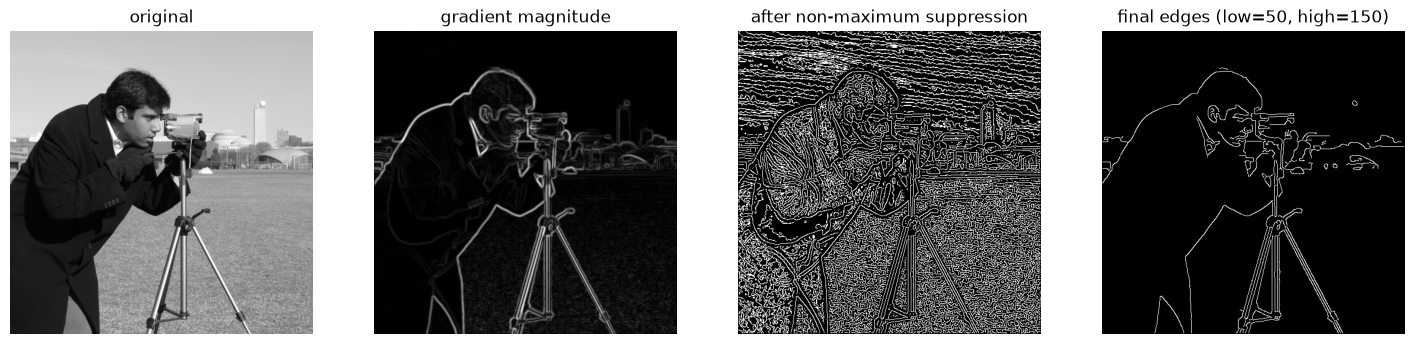

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(image); ax[0].set_title("original")
ax[1].imshow(magnitude); ax[1].set_title("gradient magnitude")
ax[2].imshow(thin > 0); ax[2].set_title("after non-maximum suppression")
ax[3].imshow(edges); ax[3].set_title(f"final edges (low={low}, high={high})")
for a in ax:
    a.axis("off")
plt.show()

## Comparison with OpenCV

`cv2.Canny` follows the same steps but does not blur the image itself, so we pass it the same
blurred image. It also uses the L1 norm $|G_x| + |G_y|$ for the magnitude unless
`L2gradient=True` is set. OpenCV also handles ties between neighbouring pixels slightly
differently, so the two results are close but not identical. The comparison below counts how
many edge pixels they share.

edge pixels  ours: 6745   OpenCV: 6737   in both: 6721


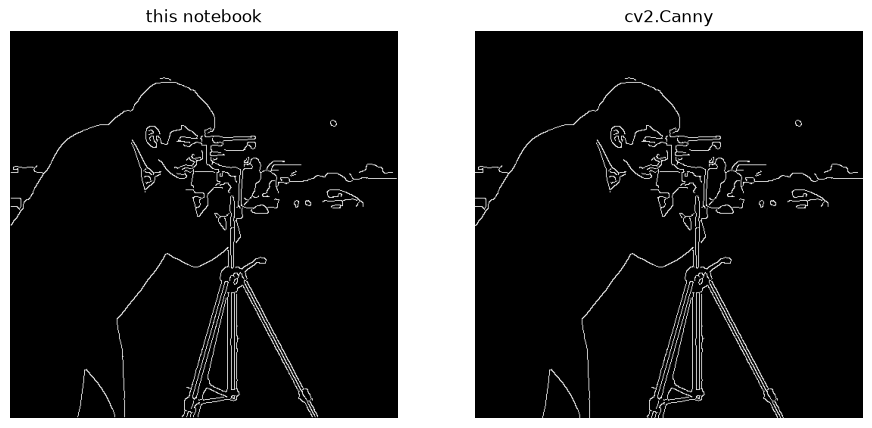

In [7]:
blurred = cv2.GaussianBlur(image, (5, 5), 1.4)
opencv = cv2.Canny(blurred, low, high, L2gradient=True)

agree = np.logical_and(edges > 0, opencv > 0).sum()
print(f"edge pixels  ours: {(edges > 0).sum()}   OpenCV: {(opencv > 0).sum()}   in both: {agree}")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
ax[0].imshow(edges); ax[0].set_title("this notebook")
ax[1].imshow(opencv); ax[1].set_title("cv2.Canny")
for a in ax:
    a.axis("off")
plt.show()

## Choosing the thresholds

The two thresholds control how much detail is kept. A common rule of thumb is a high threshold
two to three times the low one.

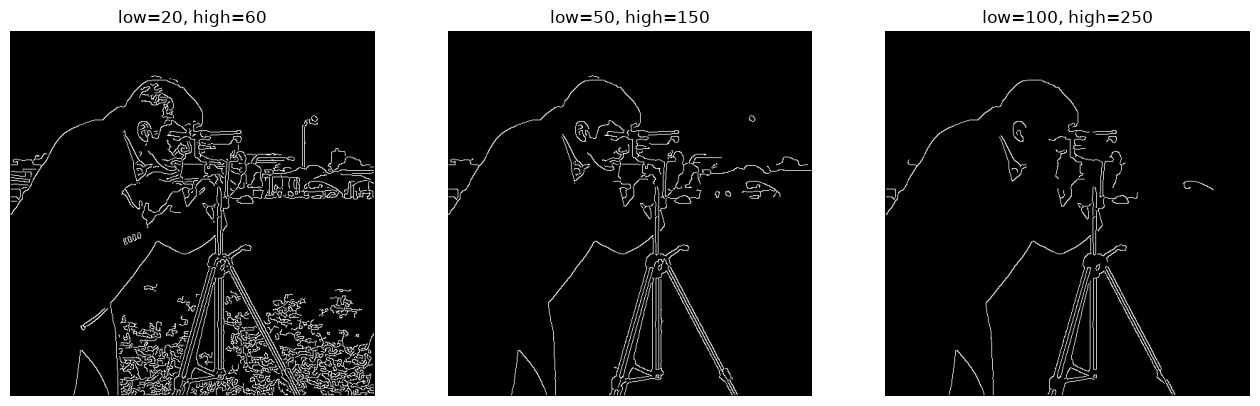

In [8]:
settings = [(20, 60), (50, 150), (100, 250)]
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
for a, (lo, hi) in zip(ax, settings):
    a.imshow(hysteresis(thin, lo, hi))
    a.set_title(f"low={lo}, high={hi}")
    a.axis("off")
plt.show()